Saving gettyimages-200184662-001-2048x2048.jpg to gettyimages-200184662-001-2048x2048.jpg


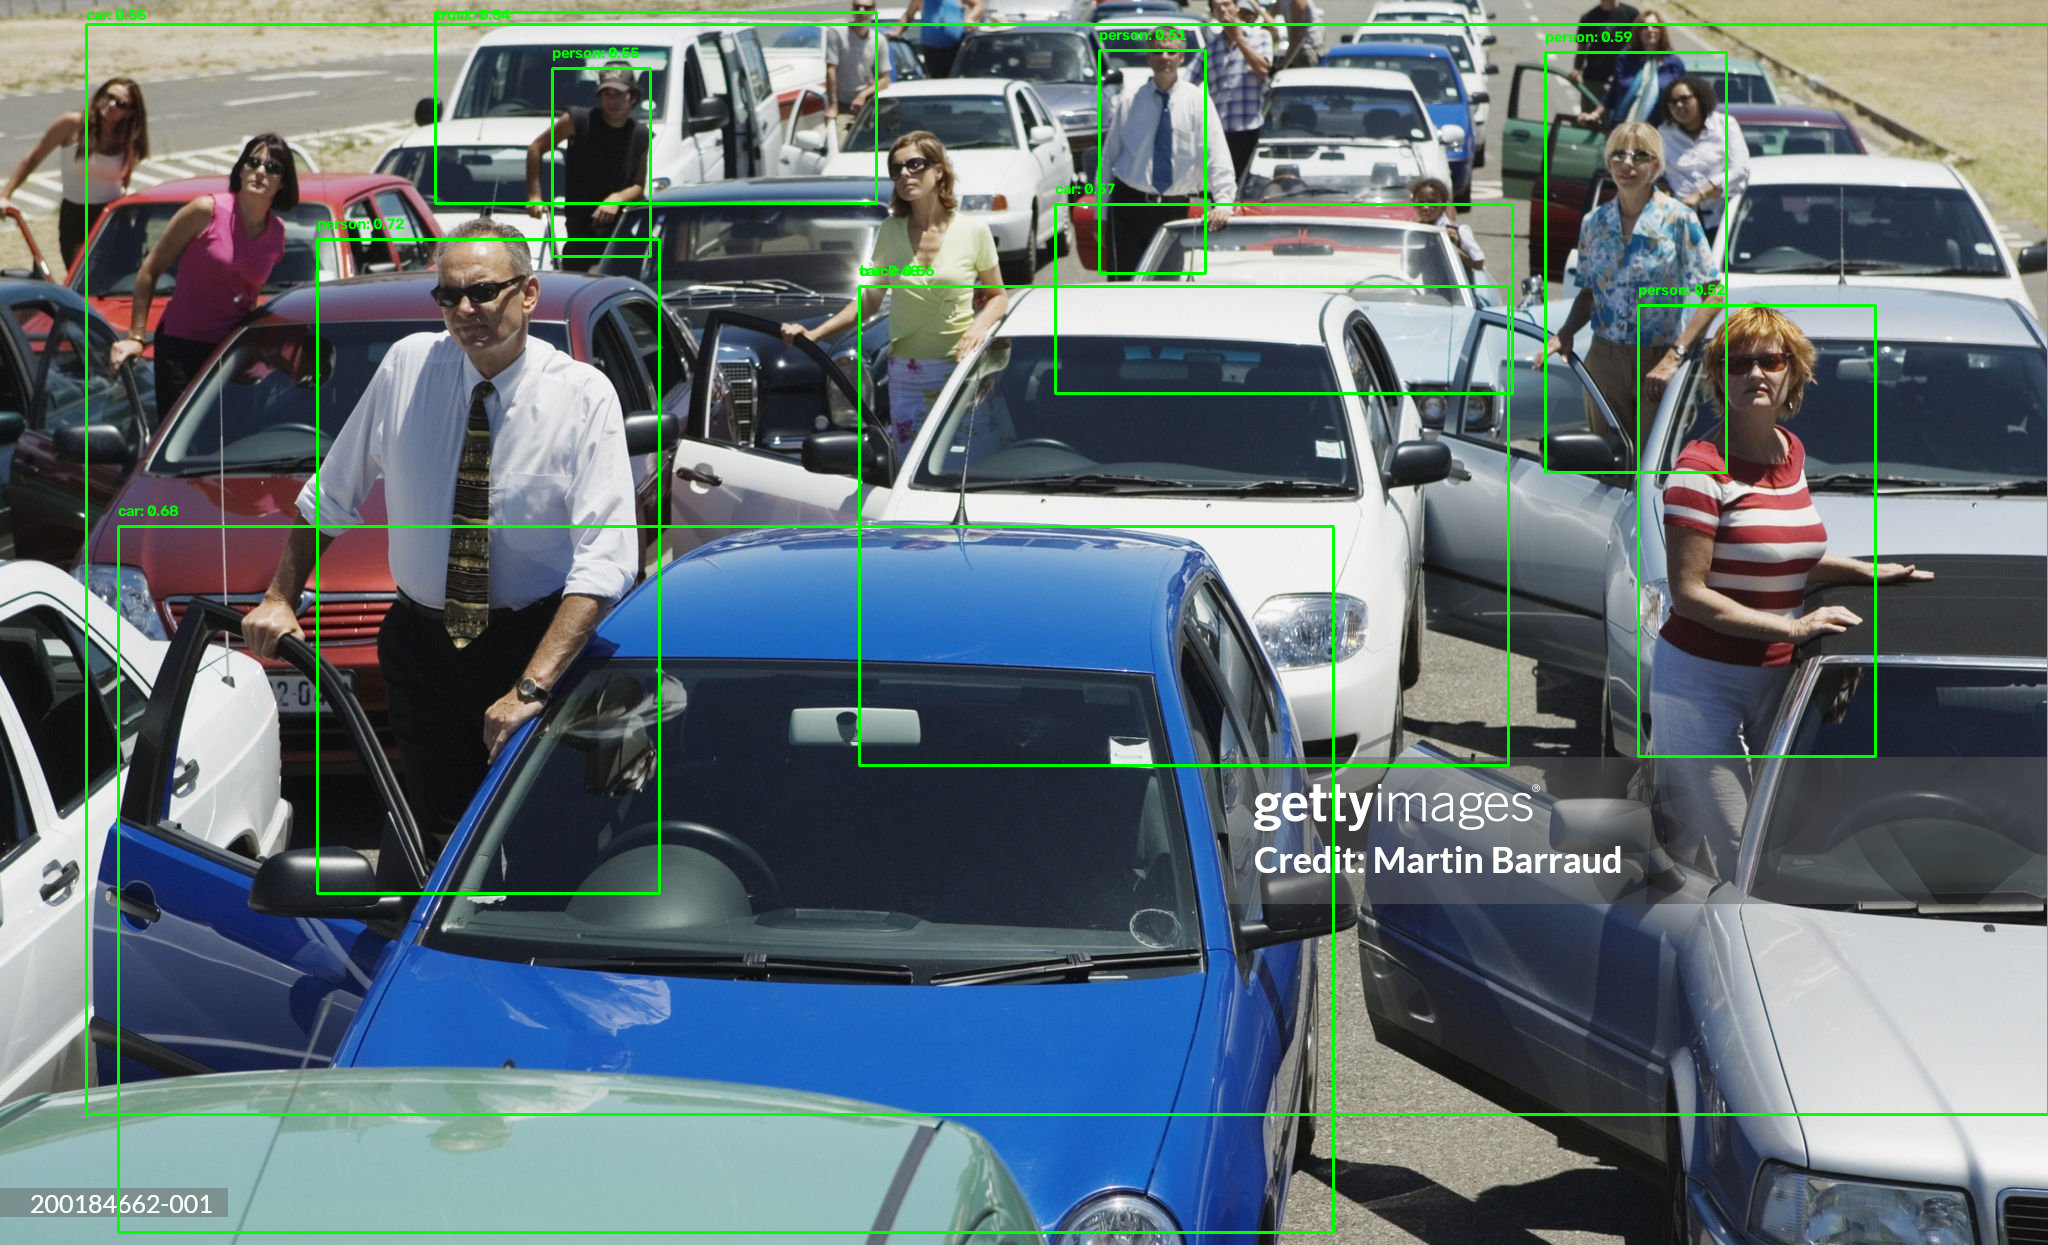

In [4]:

import tensorflow_hub as hub
import tensorflow as tf
import numpy as np
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

# 2. LOAD THE PRE-TRAINED DETECTOR
MODEL_URL = "https://tfhub.dev/tensorflow/ssd_mobilenet_v2/2"
detector = hub.load(MODEL_URL)

# 3. CLASS NAMES
COCO_CLASSES = [
    "person", "bicycle", "car", "motorcycle", "airplane", "bus",
    "train", "truck", "boat", "traffic light", "fire hydrant", "stop sign",
    "parking meter", "bench", "bird", "cat", "dog", "horse", "sheep", "cow",
    "elephant", "bear", "zebra", "giraffe", "backpack", "umbrella", "handbag",
    "tie", "suitcase", "frisbee", "skis", "snowboard", "sports ball",
    "kite", "baseball bat", "baseball glove", "skateboard", "surfboard",
    "tennis racket", "bottle", "wine glass", "cup", "fork", "knife", "spoon",
    "bowl", "banana", "apple", "sandwich", "orange", "broccoli", "carrot",
    "hot dog", "pizza", "donut", "cake", "chair", "couch", "potted plant",
    "bed", "dining table", "toilet", "TV", "laptop", "mouse", "remote",
    "keyboard", "cell phone", "microwave", "oven", "toaster", "sink",
    "refrigerator", "book", "clock", "vase", "scissors", "teddy bear",
    "hair drier", "toothbrush"
]


def detect_objects_with_boxes(image_path, detector):
    """Run the detector on one image and return the image with boxes drawn."""
    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    orig_image = image.copy()

    input_tensor = tf.convert_to_tensor(image)
    input_tensor = input_tensor[tf.newaxis, ...]

    detections = detector(input_tensor)

    num_detections = int(detections["num_detections"])
    detection_boxes = detections["detection_boxes"].numpy()[0]
    detection_classes = (
        detections["detection_classes"].numpy()[0].astype(np.int32)
    )
    detection_scores = detections["detection_scores"].numpy()[0]

    confidence_threshold = 0.5

    for i in range(num_detections):
        score = detection_scores[i]

        if score > confidence_threshold:
            box = detection_boxes[i]
            h, w, _ = orig_image.shape

            # Bounding boxes are normalized fractions.
            y_min, x_min, y_max, x_max = box
            x_min = int(x_min * w)
            x_max = int(x_max * w)
            y_min = int(y_min * h)
            y_max = int(y_max * h)

            class_id = detection_classes[i]
            class_name = (
                COCO_CLASSES[class_id - 1]
                if 1 <= class_id <= len(COCO_CLASSES)
                else "Unknown"
            )

            label = f"{class_name}: {score:.2f}"

            cv2.rectangle(
                orig_image,
                (x_min, y_min),
                (x_max, y_max),
                (0, 255, 0),
                2
            )

            cv2.putText(
                orig_image,
                label,
                (x_min, max(y_min - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (0, 255, 0),
                2
            )

    return orig_image


# 4. RUN IT: Upload an image, detect objects, and display the result.
uploaded = files.upload()
image_path = next(iter(uploaded))

result_image = detect_objects_with_boxes(image_path, detector)
cv2_imshow(result_image)

